# GenMol - Basics

## Setup
This notebook assumes that the NIM is running! Ports for the NIMs:
- AlphaFold2: 8081
- MolMIM: 8082
- **GenMOL: 8083**
- diffdock : 8084


In [1]:
#!pip install safe-mol datamol pandas numpy rdkit matplotlib 2>/dev/null | tail -n 1

In [2]:
#!pip install safe-mol datamol 2>/dev/null | tail -n 1

In [3]:
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.utils import Utils

from rdkit import Chem
from rdkit.Chem import Draw

# SAFE <> SMILES conversion
import safe as sf
import datamol as dm

import pandas as pd

GENMOL_HOST = 'http://127.0.0.1:8083'
gm = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")


## Test NIM availability

In [4]:
!curl {GENMOL_HOST}/v1/health/ready

true

## Define Seeds and used Seed for generation

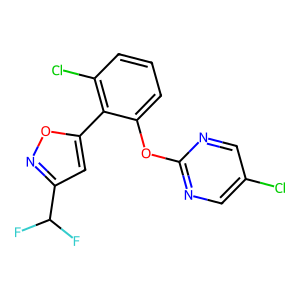

In [5]:
#Seed 1
m1 = "FC(F)C1C=C(ON=1)C1=C(C=CC=C1Cl)OC1N=CC(Cl)=CN=1"
m1_name = "BCS-DJ68924"

seed_mol_m1  = dm.to_mol(m1)
display(dm.to_image(seed_mol_m1))

In [6]:
# define the seed to be used in the notebook
m_seq = m1
seed_mol = seed_mol_m1

## check SAFE conversion & Reconstruction

In [7]:
safe_str = sf.encode(seed_mol)
print(f"SMILES: {m_seq}")
print(f"SAFE:   {safe_str}\n represented using {len(safe_str.split('.'))} fragments")

SMILES: FC(F)C1C=C(ON=1)C1=C(C=CC=C1Cl)OC1N=CC(Cl)=CN=1
SAFE:   c16c4cccc1Cl.c13ncc(Cl)cn1.c15cc6on1.FC5F.O34
 represented using 5 fragments


In [13]:
safe_str

'c16c4cccc1Cl.c13ncc(Cl)cn1.c15cc6on1.FC5F.O34'

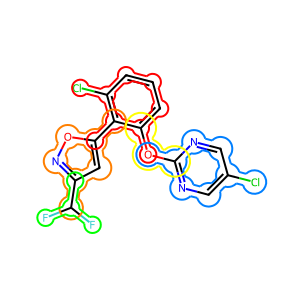

In [8]:
sf.to_image(safe_str)

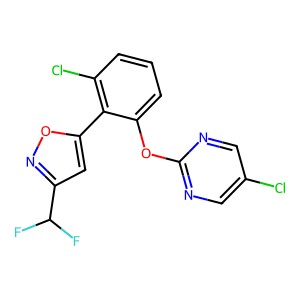

In [15]:
testreconstructed = dm.to_mol(safe_str) #safe_str)
display(dm.to_image(testreconstructed))

# Base Generation

Just a test generation to see if model is woring... basically the "de novo" way to generate molecules

In [16]:
result = gm.produce([m_seq], 100)

In [17]:
print(len(result))
print(result[0])
print(m_seq)

1
COc1ccc(OC)c(NC(=O)C2=COCCC2)c1NC(C)=O
FC(F)C1C=C(ON=1)C1=C(C=CC=C1Cl)OC1N=CC(Cl)=CN=1


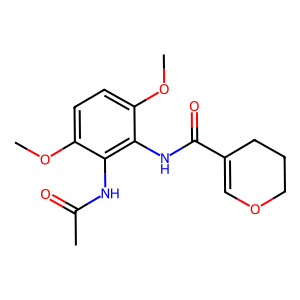

In [18]:
res_mol  = dm.to_mol(result[0])
display(dm.to_image(res_mol))

# Motif-Extension or Scaffold-Decoration

input is single fragment

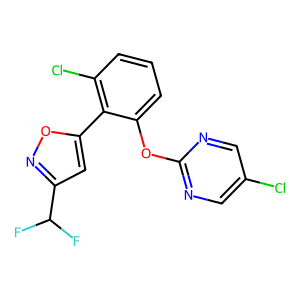

In [19]:
#draw original mol
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

### Example 1: first fragment

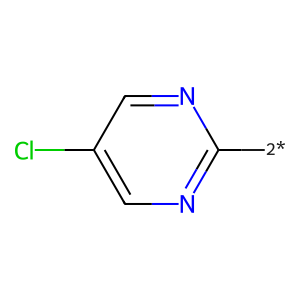

In [20]:
# add wildcard to a fragment
smiles_masked_1 = '[2*]C1=NC=C(Cl)C=N1'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [24]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_1)
safe_to_gen
molecules_e1 = gm.inference(smiles = '[*{8-27}].'+ safe_to_gen, num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e1)

75

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


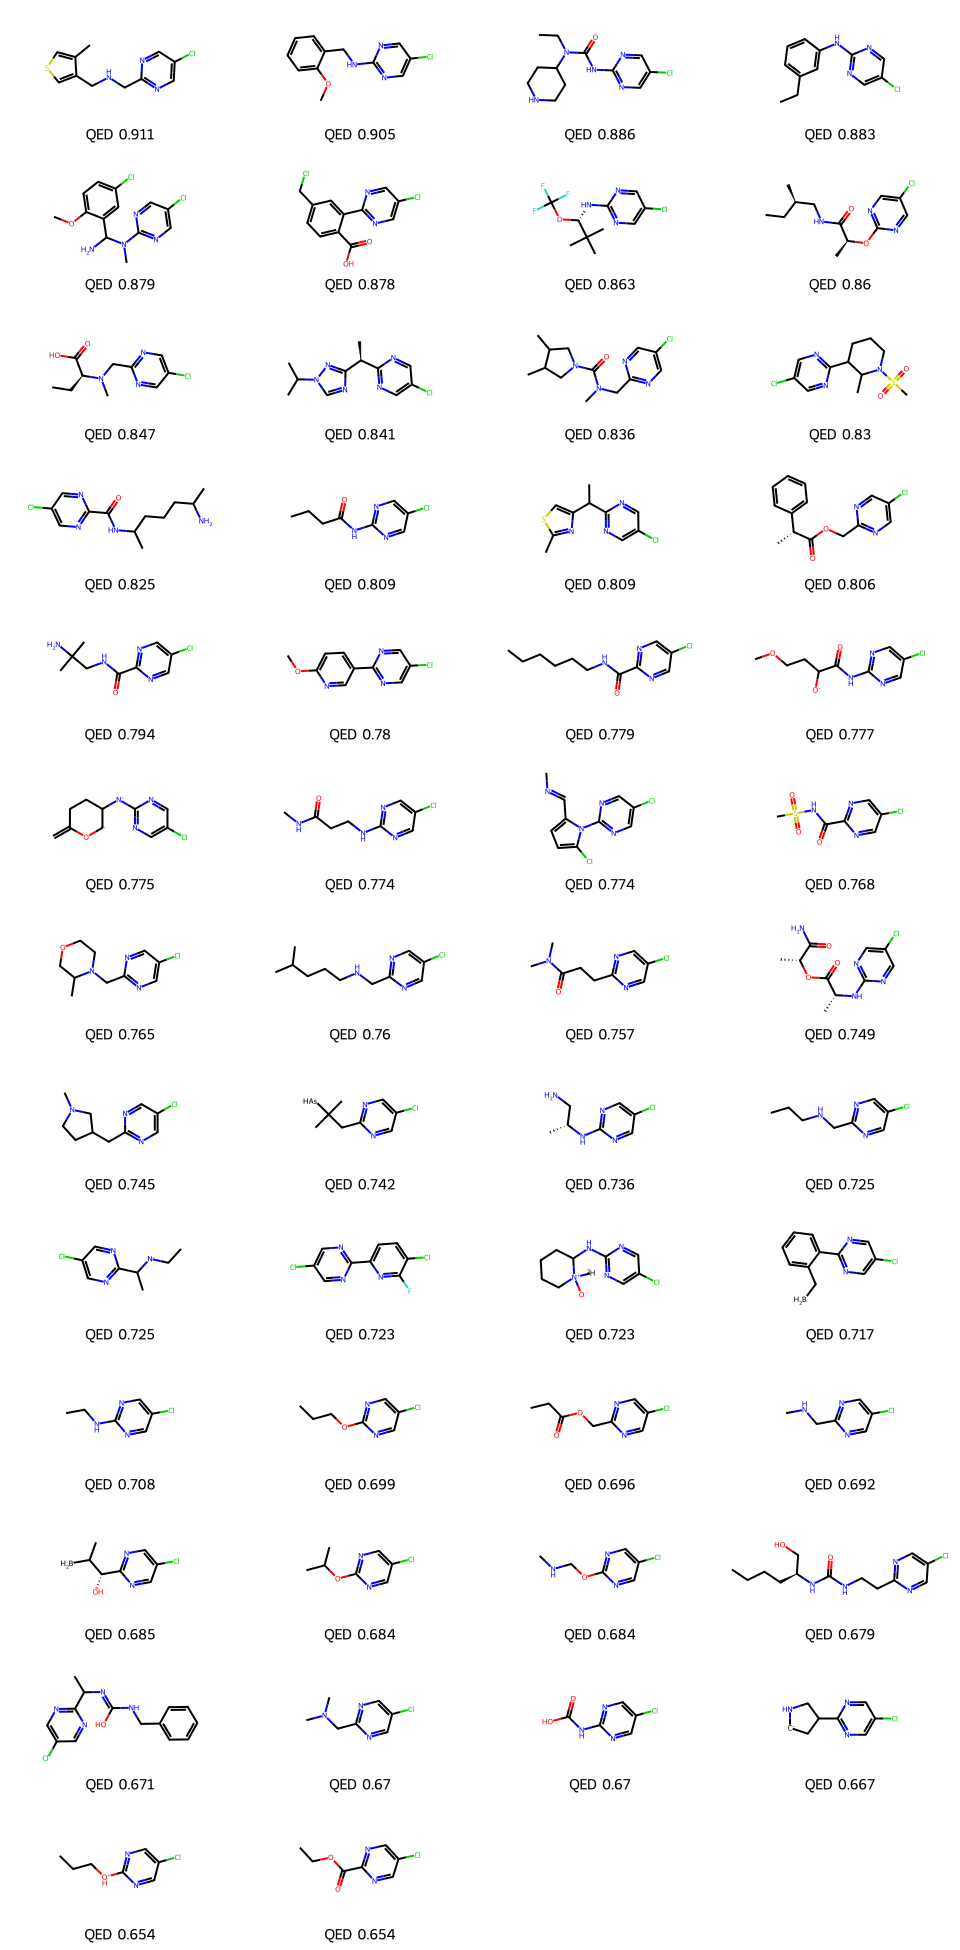

In [25]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e1]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e1])

In [26]:
# Create a DataFrame + add results
df_results = pd.DataFrame(molecules_e1)

## Example 2: second fragment

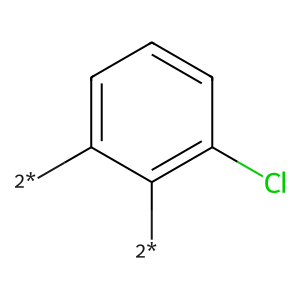

In [27]:
# add wildcard to a fragment
smiles_masked_2 = '[2*]C1=CC=CC(Cl)=C1[2*]'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_2))

In [28]:
# generate with the masked smiels adding the wilcard to both ends
safe_to_gen = Utils.smiles2safe(smiles_masked_2)
safe_to_gen
molecules_e2 = gm.inference(smiles =  '[*{10-28}].' + safe_to_gen + '.[*{10-28}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e2)

82

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


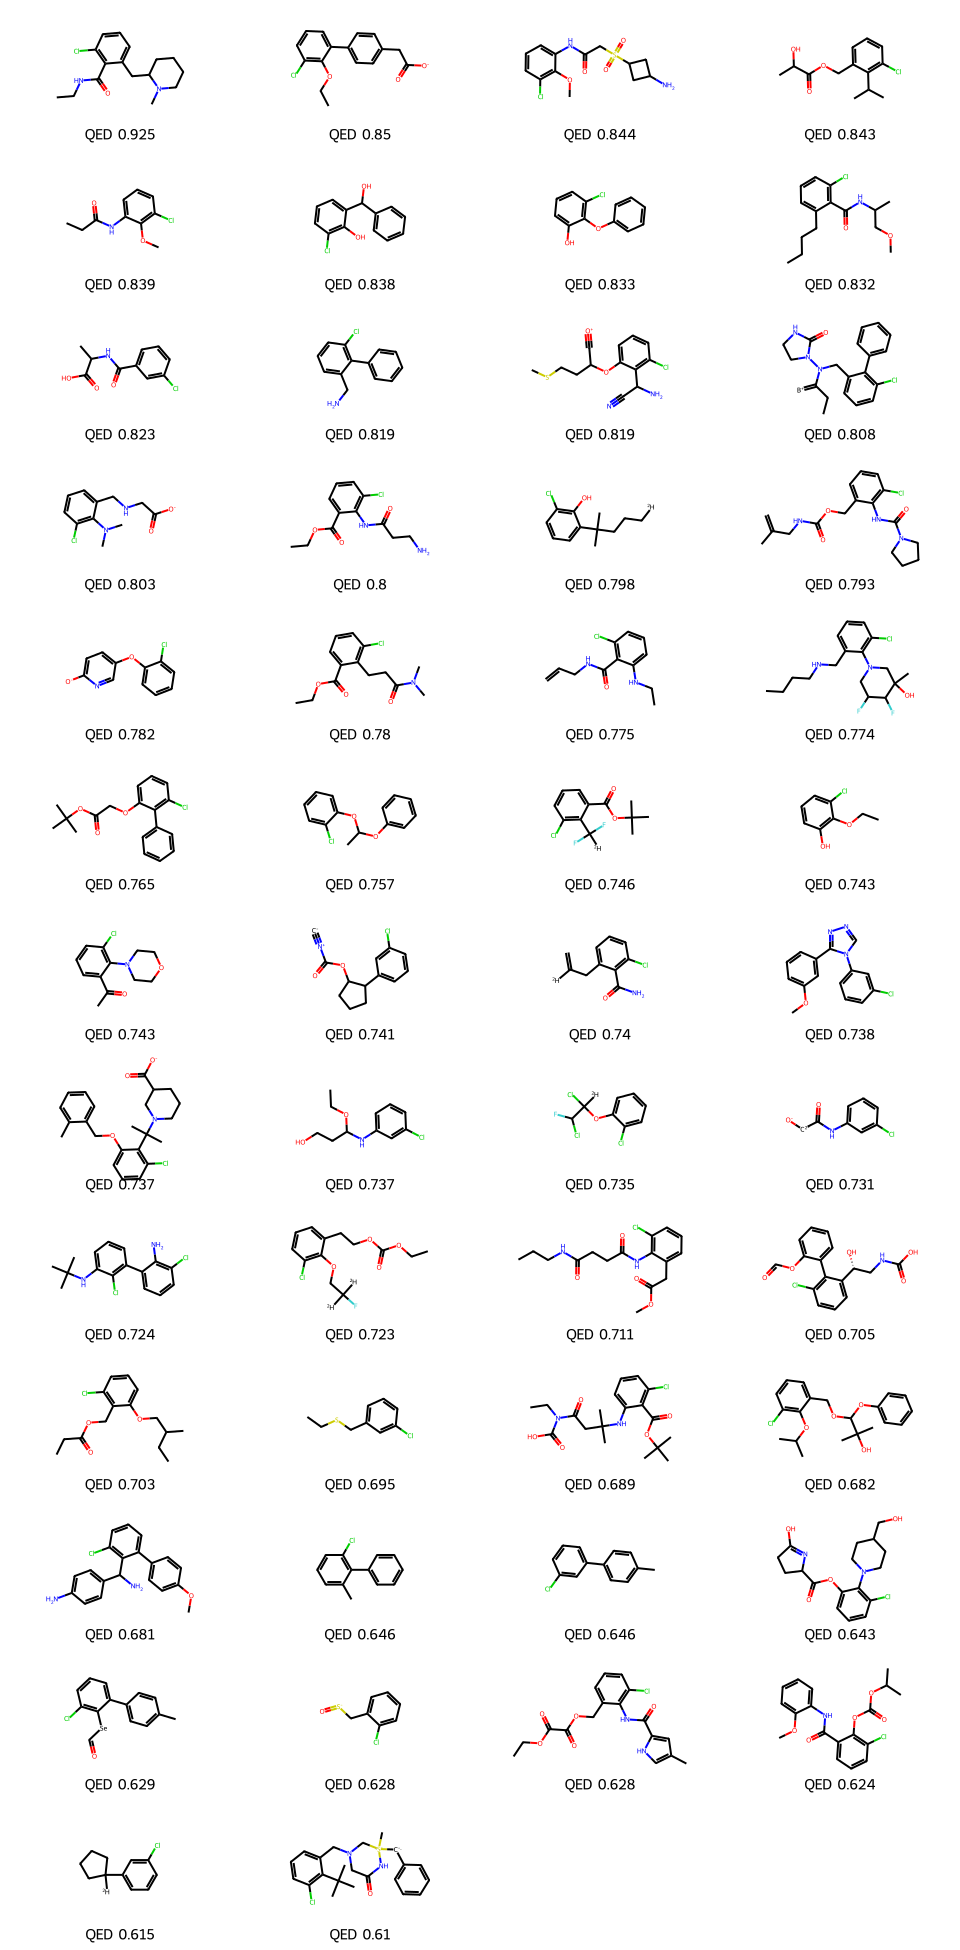

In [29]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e2]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e2])

In [30]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e2)], ignore_index=True)

In [31]:
len(df_results)

157

## Example 3: third fragment

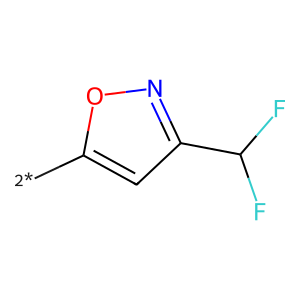

In [32]:
# add wildcard to a fragment
smiles_masked_3 = 'FC(F)C1=NOC([2*])=C1'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_3))

In [37]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_3)
safe_to_gen
molecules_e3 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e3)

50

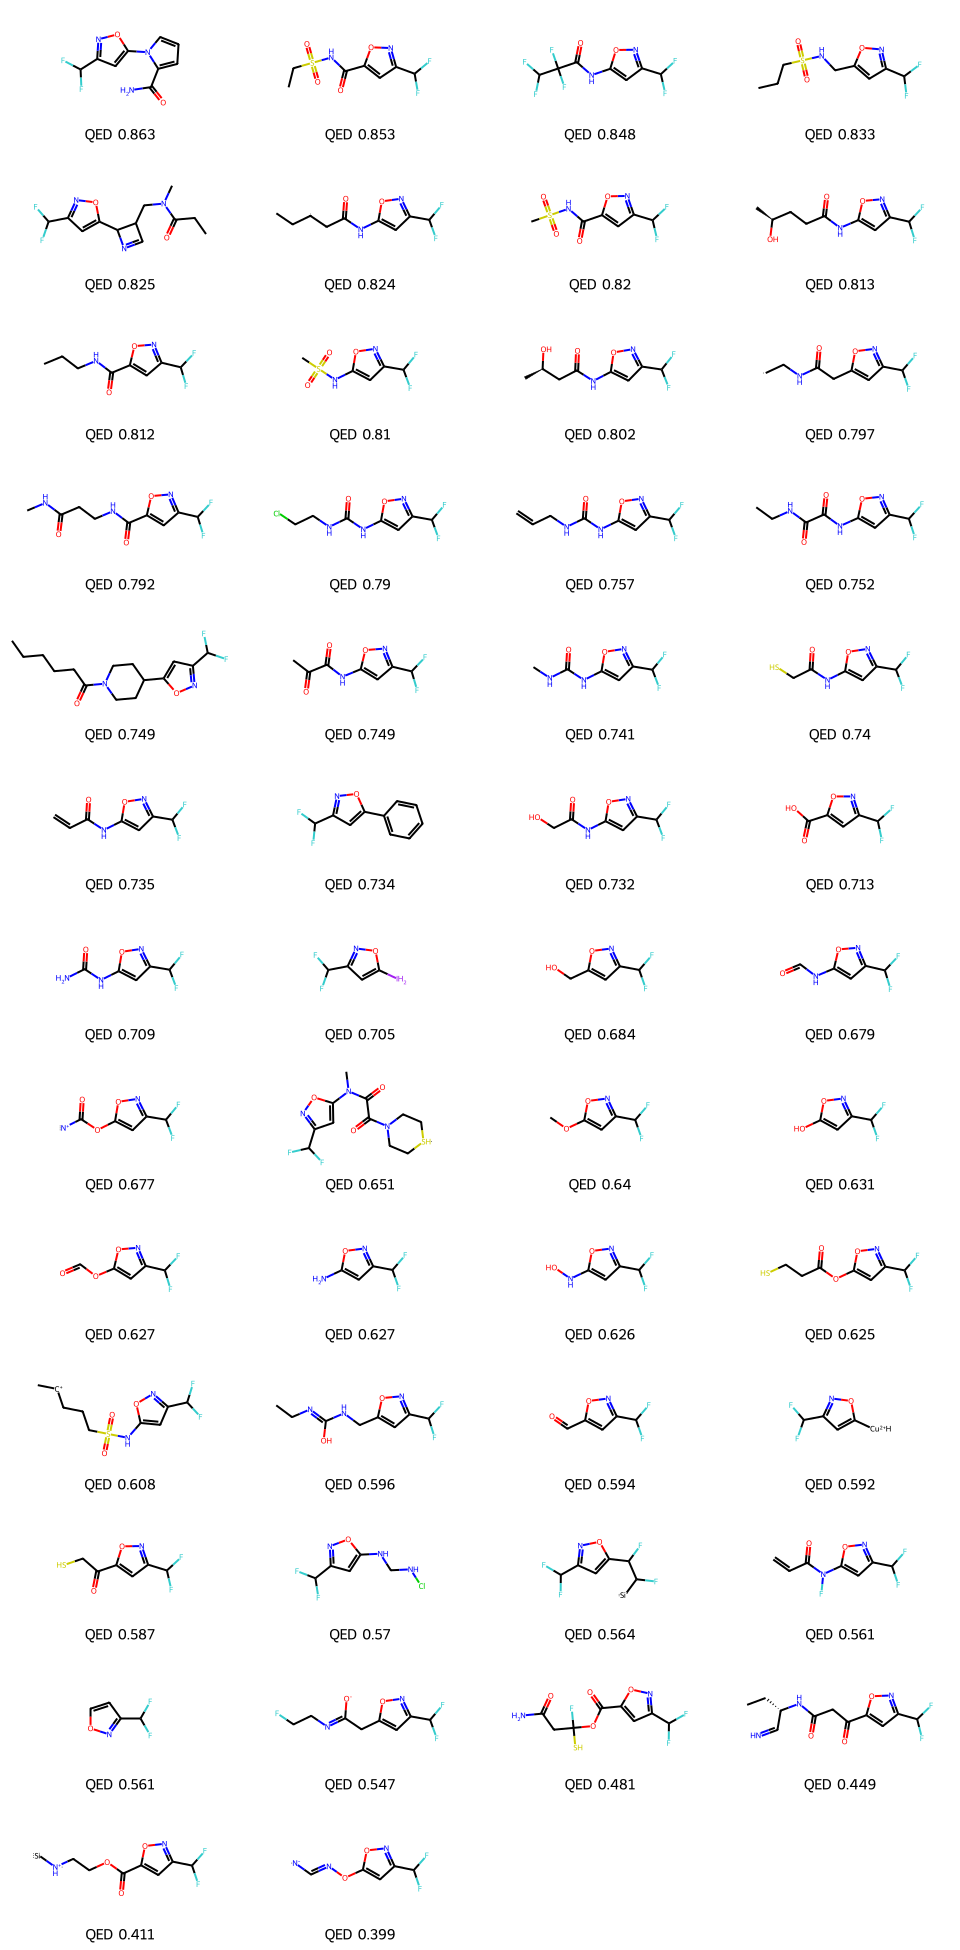

In [38]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e3]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e3])

In [39]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e3)], ignore_index=True)

In [40]:
len(df_results)

213

# Fragment based generation 
(Linker generation / Scaffold morphing)

## Mask at the end

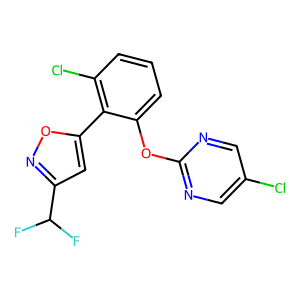

In [41]:
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

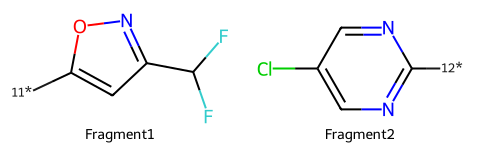

In [44]:
frag1, frag2 =  'FC(F)C1=NOC([11*])=C1', '[12*]C1=NC=C(Cl)C=N1'

Draw.MolsToGridImage([Chem.MolFromSmiles(frag1), Chem.MolFromSmiles(frag2)], 
                      molsPerRow=2, subImgSize=(240, 150), legends=['Fragment1', 'Fragment2'])

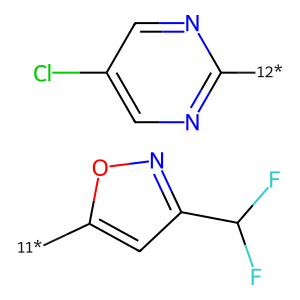

In [45]:
smiles_joint = '.'.join([frag1, frag2])
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [46]:
# mask at the end
input_text = Utils.smiles2safe(smiles_joint) + '.[*{5-27}]'
input_text

'c13ncc(Cl)cn1.c14cc2on1.FC4F.[*{5-27}]'

In [47]:
molecules_e4 = gm.inference(smiles=input_text, temperature =2.0, noise =1.0, num_molecules=1000, step_size=1)
len(molecules_e4)

58

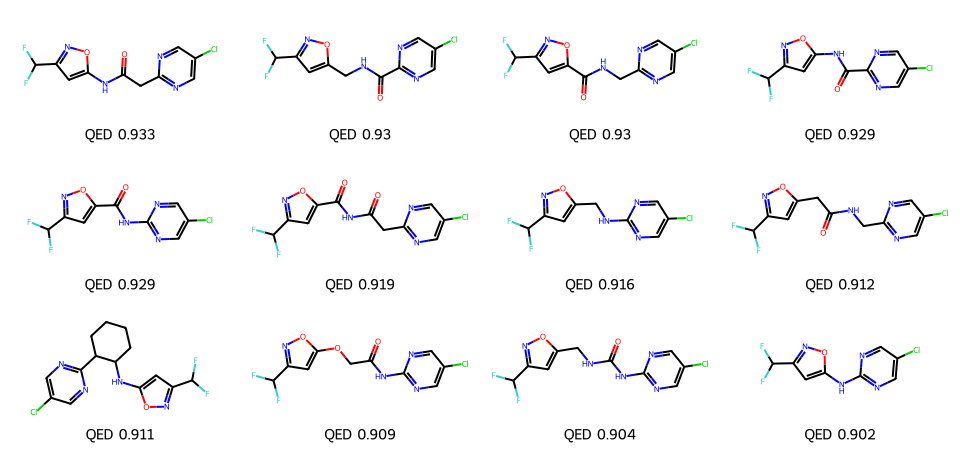

In [48]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e4[:12]]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e4[:12]])

In [49]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e4)], ignore_index=True)
print(len(df_results))
df_results.head()

271


,smiles,score
0,Cc1cscc1CNCc1ncc(Cl)cn1,0.911
1,COc1ccccc1CNc1ncc(Cl)cn1,0.905
2,CCN(C(=O)Nc1ncc(Cl)cn1)C1CCNCC1,0.886
3,CCc1cccc(Nc2ncc(Cl)cn2)c1,0.883
4,COc1ccc(Cl)cc1C(N)N(C)c1ncc(Cl)cn1,0.879


## Mask in the center

FC(F)C1=NOC([11*])=C1.[12*]C1=NC=C(Cl)C=N1


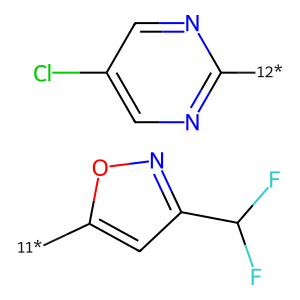

In [50]:
smiles_joint = '.'.join([frag1, frag2])
print(smiles_joint)
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [51]:
#what sub-fragments are in frag1 
text_frag1 = Utils.smiles2safe(frag1).split('.')
text_frag1

['c13cc2on1', 'FC3F']

In [52]:
#what sub-fragments are in frag2
text_frag2 = Utils.smiles2safe(frag2).split('.')
text_frag2

['c12ncc(Cl)cn1']

In [53]:
#what sub-fragments are in the full mol?
input_text = Utils.smiles2safe(smiles_joint).split('.')
input_text

['c13ncc(Cl)cn1', 'c14cc2on1', 'FC4F']

In [54]:
input_text[:1]

['c13ncc(Cl)cn1']

In [55]:
# select where to set mask
input_w_mask = '.'.join(input_text[:1]) + '.[*{5-20}].' + '.'.join(input_text[1:])
input_w_mask

'c13ncc(Cl)cn1.[*{5-20}].c14cc2on1.FC4F'

In [56]:
molecules_e5 = gm.inference(smiles = input_w_mask, temperature = 2.0, noise = 1.0, num_molecules=1000)
len(molecules_e5)

60

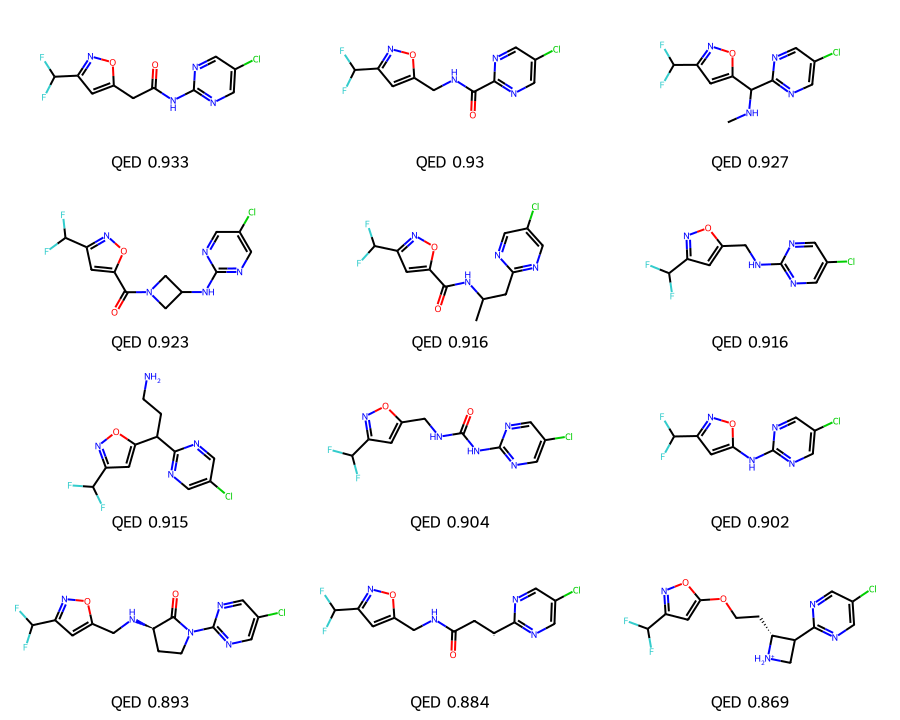

In [57]:
Draw.MolsToGridImage([Chem.MolFromSmiles(_['smiles']) for _ in molecules_e5[:12]], 
                      molsPerRow=3, subImgSize=(300, 180), legends=['QED ' + str(_['score']) for _ in molecules_e5[:12]])

In [58]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e5)], ignore_index=True)
print(len(df_results))
df_results.head()

331


,smiles,score
0,Cc1cscc1CNCc1ncc(Cl)cn1,0.911
1,COc1ccccc1CNc1ncc(Cl)cn1,0.905
2,CCN(C(=O)Nc1ncc(Cl)cn1)C1CCNCC1,0.886
3,CCc1cccc(Nc2ncc(Cl)cn2)c1,0.883
4,COc1ccc(Cl)cc1C(N)N(C)c1ncc(Cl)cn1,0.879


# SAVE Data

In [59]:
m1_name

'BCS-DJ68924'

In [60]:
#df_results.to_csv(f"../../data/interim/genmol/{m1_name}_R1_testmulti.csv", index=False)